# Jagran Lakecity University
## Faculty of Science and Technology
### BTech CSE

---

## Practical Record: Assignment 3 - Module 3
### **Practical 8: Particle Swarm Optimization (PSO)**

| Academic Details | Information |
| :--- | :--- |
| **Course** | Soft Computing |
| **Module** | Module III: Genetic Algorithms and Evolutionary Computing |
| **Student Name** | *Aakash Sarang* |
| **Enrollment No.** | *2023BTCSE001* |
| **Academic Session** | 2026 – 2027 |

---

### 1. Aim
To implement a simple Particle Swarm Optimization (PSO) algorithm for solving an optimization problem using Python.

### 2. Theory: Particle Swarm Optimization

PSO is a swarm-intelligence algorithm inspired by bird flocking. Each particle $i$ has position $\mathbf{x}_i$, velocity $\mathbf{v}_i$, personal best $\mathbf{p}_i$, and shares the global best $\mathbf{g}$:

$$\mathbf{v}_i^{(t+1)} = w \mathbf{v}_i^{(t)} + c_1 r_1 (\mathbf{p}_i - \mathbf{x}_i^{(t)}) + c_2 r_2 (\mathbf{g} - \mathbf{x}_i^{(t)})$$
$$\mathbf{x}_i^{(t+1)} = \mathbf{x}_i^{(t)} + \mathbf{v}_i^{(t+1)}$$

We minimize the 2D Sphere function $f(x, y) = x^2 + y^2$.

### 3. Step 1: Implementing PSO and Plotting Convergence

Global Best Position: [-4.0e-04 -6.9e-05]
Global Best Value:    0.00000016


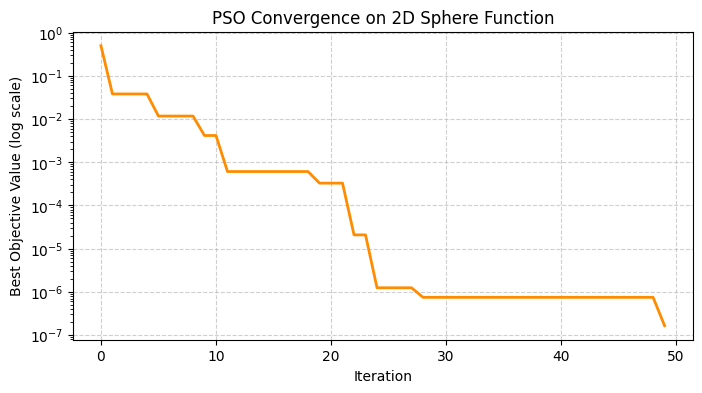

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

def sphere(x):
    return np.sum(x**2, axis=-1)

n_particles, dim, iters = 25, 2, 50
w, c1, c2 = 0.7, 1.5, 1.5
bounds = (-10, 10)

pos = np.random.uniform(bounds[0], bounds[1], (n_particles, dim))
vel = np.random.uniform(-1, 1, (n_particles, dim))
pbest_pos = pos.copy()
pbest_val = sphere(pos)
gbest_pos = pbest_pos[np.argmin(pbest_val)].copy()
gbest_val = np.min(pbest_val)

history = []
for _ in range(iters):
    r1 = np.random.rand(n_particles, dim)
    r2 = np.random.rand(n_particles, dim)
    vel = w * vel + c1 * r1 * (pbest_pos - pos) + c2 * r2 * (gbest_pos - pos)
    pos = np.clip(pos + vel, bounds[0], bounds[1])

    vals = sphere(pos)
    improved = vals < pbest_val
    pbest_pos[improved] = pos[improved]
    pbest_val[improved] = vals[improved]

    if np.min(pbest_val) < gbest_val:
        gbest_val = np.min(pbest_val)
        gbest_pos = pbest_pos[np.argmin(pbest_val)].copy()

    history.append(gbest_val)

print(f"Global Best Position: {np.round(gbest_pos, 6)}")
print(f"Global Best Value:    {gbest_val:.8f}")

plt.figure(figsize=(8, 4))
plt.semilogy(history, color='darkorange', linewidth=2)
plt.title("PSO Convergence on 2D Sphere Function")
plt.xlabel("Iteration")
plt.ylabel("Best Objective Value (log scale)")
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

### 4. Conclusion
We implemented PSO from scratch and verified its rapid convergence to the global minimum $(0, 0)$ of the Sphere function.